# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
# Si data/raw/wine.csv no existe, se genera desde el dataset Wine de scikit-learn
# (178 vinos, 13 variables químicas, 3 cultivares) con la columna "target".
if not (RAW_DATA_DIR / "wine.csv").exists():
    from sklearn.datasets import load_wine
    RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
    load_wine(as_frame=True).frame.to_csv(RAW_DATA_DIR / "wine.csv", index=False)
    print("wine.csv generado en", RAW_DATA_DIR)
else:
    print("wine.csv ya existe")

wine.csv generado en /home/claude/wine/data/raw


In [4]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

df = pd.read_csv(DATA_PATH)
print("Archivo cargado:", DATA_PATH.name)
df.head()

Archivo cargado: wine.csv


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [5]:
print("Forma:", df.shape)
print("\nTipos de datos:")
print(df.dtypes.to_string())

print("\nNulos por columna (total):", int(df.isna().sum().sum()))
print(df.isna().sum()[df.isna().sum() > 0])

n_dup = int(df.duplicated().sum())
print("\nFilas duplicadas:", n_dup)

print("\nDistribución de target:")
dist = pd.DataFrame({"n": df["target"].value_counts().sort_index(),
                     "%": (df["target"].value_counts(normalize=True).sort_index() * 100).round(1)})
print(dist.to_string())

print("\nValores únicos de target:", sorted(df["target"].unique()))
print("Columnas constantes:", [c for c in df.columns if df[c].nunique() <= 1])
print("Valores infinitos:", int(np.isinf(df.select_dtypes("number")).sum().sum()))
df.describe().T.round(2)

Forma: (178, 14)

Tipos de datos:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64

Nulos por columna (total): 0
Series([], dtype: int64)

Filas duplicadas: 0

Distribución de target:
         n     %
target          
0       59  33.1
1       71  39.9
2       48  27.0

Valores únicos de target: [np.int64(0), np.int64(1), np.int64(2)]
Columnas constantes: []
Valores infinitos: 0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


**Conclusión de calidad:**

El dataset tiene **178 filas, 13 variables numéricas (float64) y la columna `target`** (entero con 3 clases: 0, 1 y 2). La revisión no encontró problemas: **0 valores nulos, 0 filas duplicadas, 0 infinitos y ninguna columna constante**. Las clases están moderadamente desbalanceadas (33.1 %, 39.9 % y 27.0 %), sin una clase dominante ni minoritaria extrema.

**Decisiones:** (1) no se imputa ni se eliminan filas, porque no hay datos faltantes ni duplicados; (2) se usa `stratify=target` para que el split conserve esas proporciones; (3) los posibles outliers y las diferencias de escala se dejan para la etapa de modelado y se aprenden solo con train; (4) con solo 178 filas, el test tendrá 36 y sus métricas serán ruidosas, así que conviene usar validación cruzada en train para elegir modelos.

## 2. Split train/test

In [6]:
TEST_SIZE = 0.20

train_df, test_df = train_test_split(
    df,
    test_size=TEST_SIZE,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

# Proporciones de clase (comprobación del estratificado)
print(pd.DataFrame({
    "original %": df["target"].value_counts(normalize=True).sort_index().mul(100).round(1),
    "train %": train_df["target"].value_counts(normalize=True).sort_index().mul(100).round(1),
    "test %": test_df["target"].value_counts(normalize=True).sort_index().mul(100).round(1),
}).to_string())

        original %  train %  test %
target                             
0             33.1     33.1    33.3
1             39.9     40.1    38.9
2             27.0     26.8    27.8


In [7]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

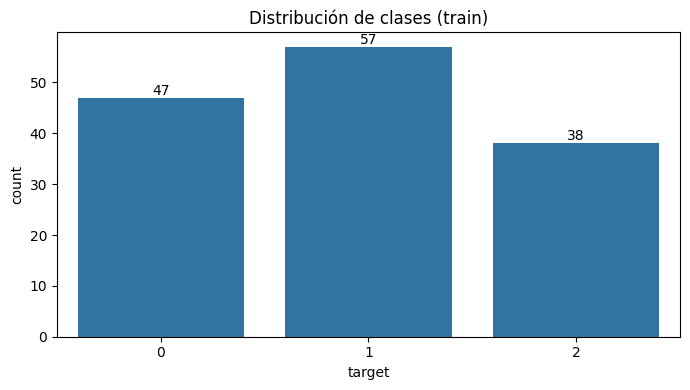

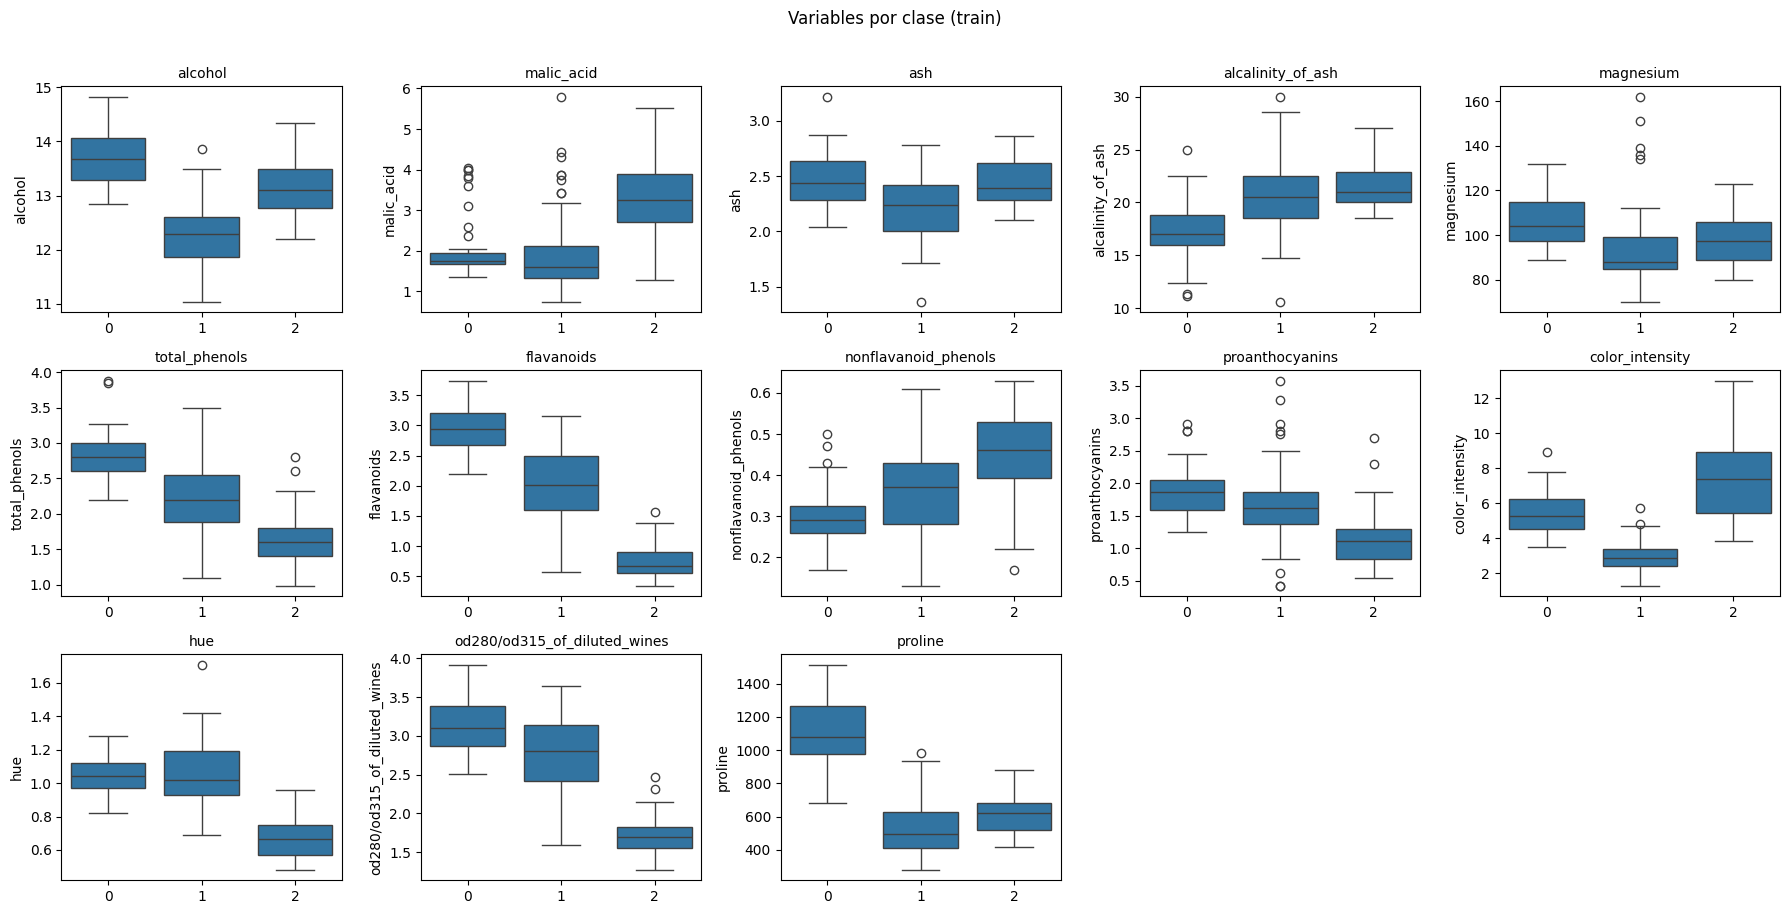

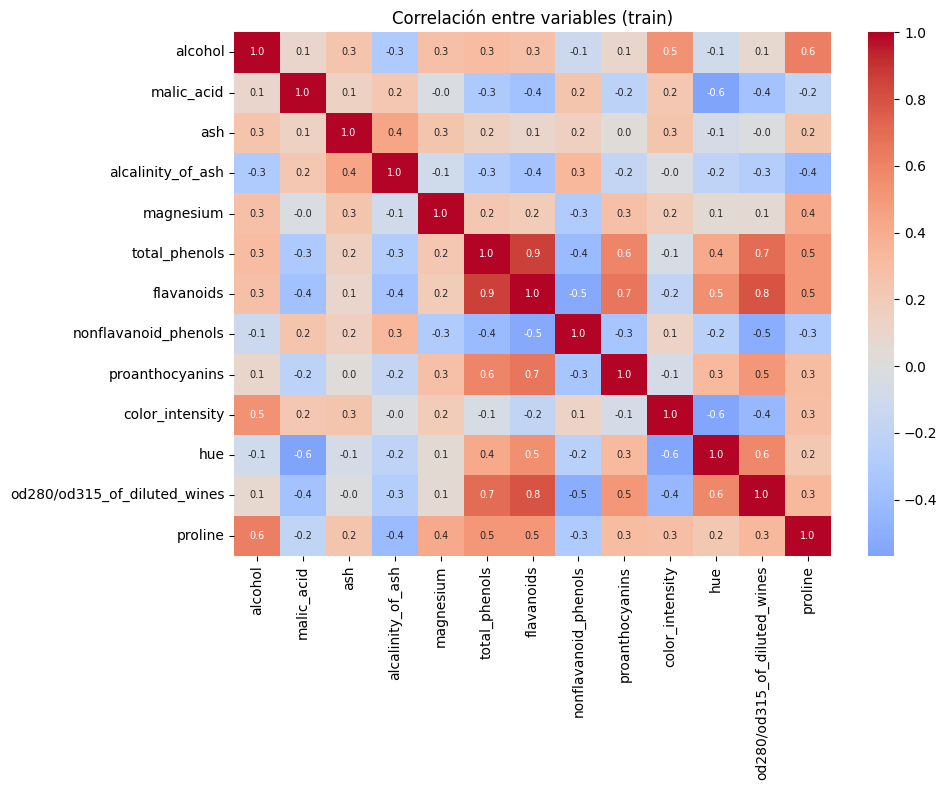

Pares más correlacionados:
      level_0                      level_1  corr
total_phenols                   flavanoids  0.86
   flavanoids od280/od315_of_diluted_wines  0.79
total_phenols od280/od315_of_diluted_wines  0.69
   flavanoids              proanthocyanins  0.66
      alcohol                      proline  0.62

Variables más discriminantes (F de ANOVA):
flavanoids                      224.8
proline                         161.5
od280/od315_of_diluted_wines    144.8
color_intensity                 103.9
alcohol                          98.5
hue                              79.5

Escalas (media / desv. estándar):
                     mean     std
proline            739.48  301.50
magnesium           99.63   14.94
alcalinity_of_ash   19.63    3.38
alcohol             12.97    0.80
...
                      mean   std
nonflavanoid_phenols  0.36  0.12
hue                   0.95  0.23
proanthocyanins       1.60  0.58

Outliers (1.5*IQR) por variable:
alcalinity_of_ash    3
magnesium

In [8]:
FEATURES = [c for c in train_df.columns if c != "target"]
class_counts = train_df["target"].value_counts().sort_index()

# --- 1) Distribución de clases ---
fig, ax = plt.subplots()
sns.countplot(data=train_df, x="target", ax=ax)
ax.set_title("Distribución de clases (train)")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout(); plt.savefig(REPORTS_DIR / "class_distribution.png", dpi=120); plt.show()

# --- 2) Boxplots por clase ---
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax)
    ax.set_title(col, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")
plt.suptitle("Variables por clase (train)", y=1.01)
plt.tight_layout(); plt.savefig(REPORTS_DIR / "boxplots_by_class.png", dpi=120); plt.show()

# --- 3) Correlaciones ---
corr = train_df[FEATURES].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlación entre variables (train)")
plt.tight_layout(); plt.savefig(REPORTS_DIR / "correlation_heatmap.png", dpi=120); plt.show()

# --- Datos de apoyo para los hallazgos ---
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("corr").reset_index().assign(abs_corr=lambda d: d["corr"].abs())
         .sort_values("abs_corr", ascending=False).head(5))
print("Pares más correlacionados:")
print(pairs[["level_0", "level_1", "corr"]].round(2).to_string(index=False))

# Ratio entre varianza entre clases y dentro de clases (F de ANOVA) como medida simple de separación
from sklearn.feature_selection import f_classif
F, _ = f_classif(train_df[FEATURES], train_df["target"])
print("\nVariables más discriminantes (F de ANOVA):")
print(pd.Series(F, index=FEATURES).sort_values(ascending=False).round(1).head(6).to_string())

print("\nEscalas (media / desv. estándar):")
print(train_df[FEATURES].agg(["mean", "std"]).T.round(2).sort_values("mean", ascending=False).head(4).to_string())
print("...")
print(train_df[FEATURES].agg(["mean", "std"]).T.round(2).sort_values("mean").head(3).to_string())

# Outliers según regla 1.5*IQR
q1, q3 = train_df[FEATURES].quantile(.25), train_df[FEATURES].quantile(.75)
iqr = q3 - q1
out = ((train_df[FEATURES] < q1 - 1.5 * iqr) | (train_df[FEATURES] > q3 + 1.5 * iqr)).sum()
print("\nOutliers (1.5*IQR) por variable:")
print(out[out > 0].sort_values(ascending=False).to_string())

**Hallazgos:**

1. **Las clases se pueden separar bien con pocas variables.** Las más discriminantes según el estadístico F de ANOVA son `flavanoids` (F≈225), `proline` (≈162), `od280/od315_of_diluted_wines` (≈145), `color_intensity` (≈104) y `alcohol` (≈99). Por ejemplo, la mediana de `flavanoids` es 2.94 / 2.01 / 0.68 para las clases 0 / 1 / 2, y la de `proline` es 1080 en la clase 0 frente a ≈500–620 en las otras dos. Se espera que incluso modelos simples (regresión logística, árboles) rindan bien, y que la clase 1 sea la más fácil de confundir con las demás en algunas variables.
2. **Hay multicolinealidad entre variables relacionadas con fenoles.** `total_phenols` y `flavanoids` tienen correlación 0.86; `flavanoids` con `od280/od315` 0.79 y `total_phenols` con `od280/od315` 0.69. Esto puede afectar la interpretación de coeficientes en modelos lineales (conviene regularizar o considerar reducir variables) y es menos relevante para modelos basados en árboles.
3. **Las escalas son muy distintas y hay pocos outliers.** `proline` tiene media ≈739 y desviación ≈302, mientras que `nonflavanoid_phenols` tiene media ≈0.36 y desviación ≈0.12. Será necesario estandarizar (ajustando el escalador solo con train, dentro de un pipeline) para modelos sensibles a la escala como regresión logística, SVM o k-NN. Por la regla 1.5·IQR hay solo 14 valores atípicos en total (como máximo 3 por variable), pocos como para eliminarlos; mejor mantenerlos y preferir modelos robustos o escalado robusto.

## 4. Persistencia de datos y contrato

In [9]:
train_out = train_df.reset_index(drop=True)
test_out = test_df.reset_index(drop=True)

train_out.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_out.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

data_contract = {
    "target": "target",
    "features": FEATURES,
    "n_features": len(FEATURES),
    "classes": sorted(int(c) for c in df["target"].unique()),
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "stratified": True,
    "n_rows": {"total": int(len(df)), "train": int(len(train_out)), "test": int(len(test_out))},
    "source": "data/raw/wine.csv",
}

with open(ARTIFACTS_DIR / "data_contract.json", "w", encoding="utf-8") as f:
    json.dump(data_contract, f, indent=2, ensure_ascii=False)

print(json.dumps(data_contract, indent=2, ensure_ascii=False))

{
  "target": "target",
  "features": [
    "alcohol",
    "malic_acid",
    "ash",
    "alcalinity_of_ash",
    "magnesium",
    "total_phenols",
    "flavanoids",
    "nonflavanoid_phenols",
    "proanthocyanins",
    "color_intensity",
    "hue",
    "od280/od315_of_diluted_wines",
    "proline"
  ],
  "n_features": 13,
  "classes": [
    0,
    1,
    2
  ],
  "random_state": 42,
  "test_size": 0.2,
  "stratified": true,
  "n_rows": {
    "total": 178,
    "train": 142,
    "test": 36
  },
  "source": "data/raw/wine.csv"
}


In [10]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.